In [ ]:
%pip install "dask[array]"

In [1]:
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path

files = sorted(Path("data/era5land").glob("*.nc"))
print(len(files), "files")   # should be 61

ds = xr.open_mfdataset(files, combine="by_coords")
print(ds)

61 files
<xarray.Dataset> Size: 17MB
Dimensions:     (valid_time: 44568, latitude: 5, longitude: 9)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 357kB 2001-12-01 ... 2006-12-31T2...
    expver      (valid_time) <U4 713kB dask.array<chunksize=(744,), meta=np.ndarray>
  * latitude    (latitude) float64 40B 51.7 51.6 51.5 51.4 51.3
  * longitude   (longitude) float64 72B -0.5 -0.4 -0.3 -0.2 ... 0.1 0.2 0.3
    number      int64 8B 0
Data variables:
    t2m         (valid_time, latitude, longitude) float32 8MB dask.array<chunksize=(744, 5, 9), meta=np.ndarray>
    d2m         (valid_time, latitude, longitude) float32 8MB dask.array<chunksize=(744, 5, 9), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-03

In [2]:
ds = ds.load()
ds = ds.drop_vars(["expver", "number"]).rename({"valid_time": "time"})

ds["t2m"] = ds["t2m"] - 273.15   # Kelvin -> °C
ds["d2m"] = ds["d2m"] - 273.15

# Relative humidity (%) from temperature and dewpoint (Magnus formula)
a, b = 17.625, 243.04
ds["rh"] = 100 * np.exp(a * ds["d2m"] / (b + ds["d2m"])) / np.exp(a * ds["t2m"] / (b + ds["t2m"]))

# Check for missing cells (e.g. Thames estuary masked as water)
print(ds["t2m"].isel(time=0).isnull().sum().item(), "missing cells out of 45")

0 missing cells out of 45


In [3]:
# City-wide hourly mean across all grid cells
hourly = ds[["t2m", "d2m", "rh"]].mean(["latitude", "longitude"]).to_dataframe()

# ERA5 is in UTC; health data are by local (London) date
hourly.index = hourly.index.tz_localize("UTC").tz_convert("Europe/London")
hourly["date"] = hourly.index.tz_localize(None).normalize()

daily = hourly.groupby("date").agg(
    era5_tmean=("t2m", "mean"),
    era5_tmax=("t2m", "max"),
    era5_tmin=("t2m", "min"),
    era5_rh=("rh", "mean"),
    n_hours=("t2m", "size"),
)

# Keep complete local days only (23 or 25 hours on clock-change days)
print(daily["n_hours"].value_counts())
daily = daily[daily["n_hours"] >= 23].drop(columns="n_hours").reset_index()
daily.head()

n_hours
24    1847
23       5
25       5
Name: count, dtype: int64


,date,era5_tmean,era5_tmax,era5_tmin,era5_rh
0,2001-12-01,10.337070,13.340511,3.394442,88.450897
1,2001-12-02,4.288823,7.522954,0.202888,92.597565
2,2001-12-03,4.780614,8.140276,1.271780,95.861366
3,2001-12-04,8.203544,10.169714,5.198014,82.052094
4,2001-12-05,8.507146,12.861743,5.556487,83.936668


missing ERA5 days: 0
correlation: 0.992
mean difference (ERA5 - dataset): -0.87 °C


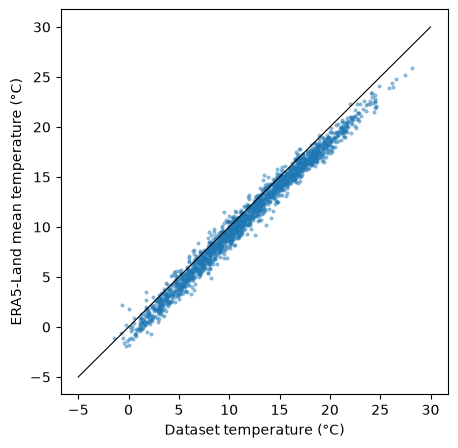

In [4]:
london = pd.read_stata("data/londondataset2002_2006.dta")
merged = london.merge(daily, on="date", how="left")

print("missing ERA5 days:", merged["era5_tmean"].isna().sum())
print("correlation:", merged[["temperature", "era5_tmean"]].corr().iloc[0, 1].round(3))
print("mean difference (ERA5 - dataset):", (merged["era5_tmean"] - merged["temperature"]).mean().round(2), "°C")

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(merged["temperature"], merged["era5_tmean"], s=4, alpha=0.4)
ax.plot([-5, 30], [-5, 30], color="black", lw=0.8)   # line of equality
ax.set_xlabel("Dataset temperature (°C)")
ax.set_ylabel("ERA5-Land mean temperature (°C)")
plt.show()

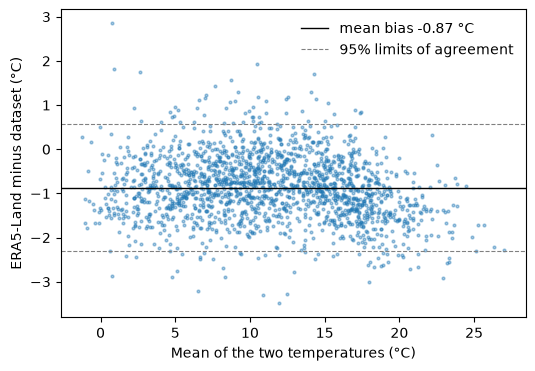

In [5]:
diff = merged["era5_tmean"] - merged["temperature"]
avg = (merged["era5_tmean"] + merged["temperature"]) / 2

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(avg, diff, s=4, alpha=0.4)
ax.axhline(diff.mean(), color="black", lw=1, label=f"mean bias {diff.mean():.2f} °C")
ax.axhline(diff.mean() + 1.96 * diff.std(), color="grey", ls="--", lw=0.8)
ax.axhline(diff.mean() - 1.96 * diff.std(), color="grey", ls="--", lw=0.8, label="95% limits of agreement")
ax.set_xlabel("Mean of the two temperatures (°C)")
ax.set_ylabel("ERA5-Land minus dataset (°C)")
ax.legend(frameon=False)
plt.show()

In [6]:
slope = np.polyfit(avg, diff, 1)[0]
print(f"bias changes by {slope:.3f} °C per 1 °C increase in temperature")

bias changes by -0.022 °C per 1 °C increase in temperature


In [8]:
fig.savefig("figures/bland_altman.png", dpi=300, bbox_inches="tight")

saved 1826 rows


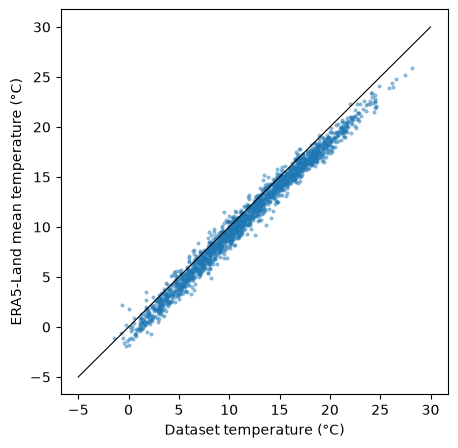

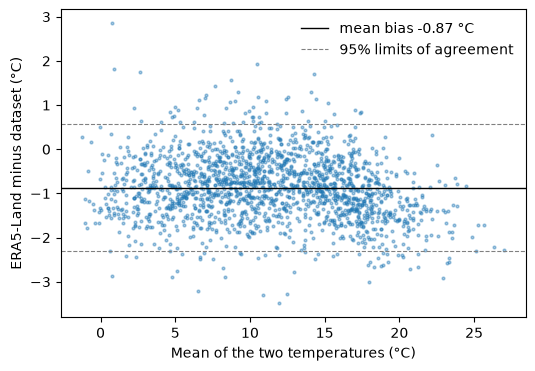

In [9]:
from pathlib import Path

Path("figures").mkdir(exist_ok=True)

# 1. The merged daily dataset (deaths + both temperatures)
merged.to_csv("data/london_merged_daily.csv", index=False)
print("saved", len(merged), "rows")

# 2. Scatter plot: ERA5 vs dataset temperature
fig1, ax = plt.subplots(figsize=(5, 5))
ax.scatter(merged["temperature"], merged["era5_tmean"], s=4, alpha=0.4)
ax.plot([-5, 30], [-5, 30], color="black", lw=0.8)
ax.set_xlabel("Dataset temperature (°C)")
ax.set_ylabel("ERA5-Land mean temperature (°C)")
fig1.savefig("figures/era5_vs_station_scatter.png", dpi=150, bbox_inches="tight")

# 3. Bland-Altman plot
diff = merged["era5_tmean"] - merged["temperature"]
avg = (merged["era5_tmean"] + merged["temperature"]) / 2
fig2, ax = plt.subplots(figsize=(6, 4))
ax.scatter(avg, diff, s=4, alpha=0.4)
ax.axhline(diff.mean(), color="black", lw=1, label=f"mean bias {diff.mean():.2f} °C")
ax.axhline(diff.mean() + 1.96 * diff.std(), color="grey", ls="--", lw=0.8)
ax.axhline(diff.mean() - 1.96 * diff.std(), color="grey", ls="--", lw=0.8, label="95% limits of agreement")
ax.set_xlabel("Mean of the two temperatures (°C)")
ax.set_ylabel("ERA5-Land minus dataset (°C)")
ax.legend(frameon=False)
fig2.savefig("figures/bland_altman.png", dpi=150, bbox_inches="tight")
plt.show()